# Atelier jour 3 — Sécurité, analyse et visualisation
## Projet fil rouge : BigData Commerce Analytics · B2 Sup de Vinci

**Objectif :** pseudonymiser les identifiants clients avec HMAC-SHA256, préparer des datasets analytiques pseudonymisés (Parquet), puis construire trois graphiques commentés.

**Prérequis :**
- MongoDB démarré (`docker start mongo`) avec les collections du TP2 (`raw_commandes`, `raw_payments`) ;
- la clé définie dans le terminal **avant** de lancer Jupyter : `export PSEUDO_KEY="..."` (Linux) ou `$env:PSEUDO_KEY="..."` (PowerShell).

> La clé n'est jamais écrite ni affichée dans ce notebook. Les données sont fictives (DummyJSON) et les paiements sont simulés.

## 0. Imports, clé secrète et fonction de pseudonymisation

In [1]:
import os
import hmac
import hashlib
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from pymongo import MongoClient

# Clé secrète lue dans l'environnement : elle n'est ni affichée ni enregistrée
CLE = os.environ.get("PSEUDO_KEY")
if not CLE:
    raise ValueError("PSEUDO_KEY n'est pas définie : faire export PSEUDO_KEY=... avant de lancer Jupyter")
SECRET = CLE.encode("utf-8")
print("Clé secrète chargée (valeur non affichée).")

def pseudonymiser(valeur):
    # HMAC-SHA256 : même identifiant + même clé = même pseudonyme
    message = str(valeur).encode("utf-8")
    return hmac.new(SECRET, message, hashlib.sha256).hexdigest()

# Dossiers de sortie
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_ANALYTIQUE = ROOT / "data" / "analytique"
GRAPHIQUES = ROOT / "resultats" / "graphiques"
DATA_ANALYTIQUE.mkdir(parents=True, exist_ok=True)
GRAPHIQUES.mkdir(parents=True, exist_ok=True)

Clé secrète chargée (valeur non affichée).


# Atelier 1 — Pseudonymiser les identifiants clients

## 1. Charger les commandes et les paiements depuis MongoDB

In [2]:
client = MongoClient("mongodb://localhost:27017")
db = client["commerce"]

commandes = pd.DataFrame(list(db["raw_commandes"].find({}, {"_id": 0})))
paiements = pd.DataFrame(list(db["raw_payments"].find({}, {"_id": 0})))

print("Commandes :", commandes.shape)
print("Paiements :", paiements.shape)

Commandes : (800, 16)
Paiements : (208, 7)


## 2. Appliquer HMAC à `user_id` dans les commandes

In [3]:
commandes["user_id_pseudo"] = commandes["user_id"].apply(pseudonymiser)

# Quelques identifiants avant / après pseudonymisation
exemple = (commandes[["user_id", "user_id_pseudo"]]
           .drop_duplicates()
           .sort_values("user_id")
           .head(5))
display(exemple)

,user_id,user_id_pseudo
0,1,088d1b3dcab3b5d06446d8d9e42fe5c919d71eb0cb1add...
4,2,a0b4a5a28ed51a8ebad8442ce81807dabd4ef575f36688...
6,3,5b626e50f34c4d29368b946e69f73a7f3a689ac89bc8a8...
12,4,9f173d0c18c88570fec2d109d828810cc44b82455579d5...
14,5,5884d3eedfb4335d98991156dd1581dd67d86ae9dc3de7...


## 3. Vérifications

In [4]:
# a) Deux commandes d'un même client donnent le même pseudonyme
pseudos_par_client = commandes.groupby("user_id")["user_id_pseudo"].nunique()
print("Clients ayant plusieurs pseudonymes :", (pseudos_par_client > 1).sum())

# Exemple : toutes les lignes du client 1
display(commandes.loc[commandes["user_id"] == 1, ["user_id", "cart_id", "product_title", "user_id_pseudo"]])

# b) Pas de collision : autant de pseudonymes que de clients
print("Clients distincts :", commandes["user_id"].nunique())
print("Pseudonymes distincts :", commandes["user_id_pseudo"].nunique())

Clients ayant plusieurs pseudonymes : 0


,user_id,cart_id,product_title,user_id_pseudo
0,1,1,Blue Frock,088d1b3dcab3b5d06446d8d9e42fe5c919d71eb0cb1add...
1,1,1,Generic Motorcycle,088d1b3dcab3b5d06446d8d9e42fe5c919d71eb0cb1add...
2,1,1,iPhone 6,088d1b3dcab3b5d06446d8d9e42fe5c919d71eb0cb1add...
3,1,1,Baseball Ball,088d1b3dcab3b5d06446d8d9e42fe5c919d71eb0cb1add...


Clients distincts : 208
Pseudonymes distincts : 208


In [5]:
# c) Les calculs par client restent possibles avec le pseudonyme
par_user_id = commandes.groupby("user_id")["discounted_line_total"].sum().round(2).sort_values().values
par_pseudo = commandes.groupby("user_id_pseudo")["discounted_line_total"].sum().round(2).sort_values().values
print("Mêmes totaux par client avec user_id et avec le pseudonyme :", (par_user_id == par_pseudo).all())

Mêmes totaux par client avec user_id et avec le pseudonyme : True


In [6]:
# d) Même clé appliquée aux paiements : même client = même pseudonyme dans les deux collections
paiements["user_id_pseudo"] = paiements["user_id"].apply(pseudonymiser)

correspondance = (commandes[["user_id", "user_id_pseudo"]].drop_duplicates()
                  .merge(paiements[["user_id", "user_id_pseudo"]].drop_duplicates(),
                         on="user_id", suffixes=("_commandes", "_paiements")))
identiques = (correspondance["user_id_pseudo_commandes"] == correspondance["user_id_pseudo_paiements"]).all()
print("Clients présents dans les deux collections :", len(correspondance))
print("Même pseudonyme dans les commandes et les paiements :", identiques)

Clients présents dans les deux collections : 208
Même pseudonyme dans les commandes et les paiements : True


## Réponses — Atelier 1

**1. Identifiants avant et après pseudonymisation**
Voir le tableau de la partie 2 : chaque `user_id` (1, 2, 3...) est remplacé par une empreinte HMAC-SHA256 de 64 caractères hexadécimaux.

**2. Pourquoi un même client garde le même pseudonyme dans plusieurs commandes et dans les paiements ?**
HMAC est déterministe : le même identifiant, avec la même clé, donne toujours le même résultat. Comme on utilise la même fonction et la même clé pour `raw_commandes` et `raw_payments`, un client a le même pseudonyme partout. On peut donc toujours regrouper ses commandes et ses paiements, sans connaître son identifiant.

**3. Pourquoi la clé secrète ne doit pas être déposée sur GitHub ou partagée avec les livrables ?**
Avec la clé, n'importe qui peut recalculer le pseudonyme de chaque `user_id` (1 à 208) et retrouver qui se cache derrière chaque pseudonyme. La protection disparaît. La clé reste donc dans une variable d'environnement, jamais dans le code, le notebook, Git ou les fichiers de résultats.

**4. Limites de la pseudonymisation et précautions**
- Ce n'est pas une anonymisation : avec la clé, ou en recoupant d'autres informations (montant, date, produits achetés), on peut ré-identifier un client. Le RGPD considère donc toujours ces données comme personnelles.
- Les `user_id` sont des petits nombres : sans clé, un simple hachage SHA-256 se casserait en testant 1 à 208. C'est pour ça qu'on utilise HMAC avec une clé secrète.
- Précautions : retirer les identifiants directs (`user_id`, `username`) des datasets, garder la clé hors du dépôt, limiter l'accès aux fichiers Parquet, ne pas les publier dans un dépôt public, et changer la clé si elle a fuité.

# Atelier 2 — Préparer les données et les visualisations

## 1. Préparer les données
Conversion des montants en numérique et des dates avec `errors="coerce"` : une valeur invalide devient `NaN` / `NaT` au lieu de faire planter le traitement, puis on l'écarte.

> Dans MongoDB, le statut du paiement s'appelle `status` (nommé `payment_status` dans le sujet).

In [7]:
commandes["discounted_line_total"] = pd.to_numeric(commandes["discounted_line_total"], errors="coerce")
commandes["order_date"] = pd.to_datetime(commandes["order_date"], errors="coerce")
paiements["amount"] = pd.to_numeric(paiements["amount"], errors="coerce")
paiements["payment_date"] = pd.to_datetime(paiements["payment_date"], errors="coerce")

print("Commandes invalides (montant ou date) :",
      commandes[["discounted_line_total", "order_date"]].isna().any(axis=1).sum())
print("Paiements invalides (montant ou date) :",
      paiements[["amount", "payment_date"]].isna().any(axis=1).sum())

commandes = commandes.dropna(subset=["discounted_line_total", "order_date"])
paiements = paiements.dropna(subset=["amount", "payment_date"])
print("Commandes conservées :", len(commandes), "| Paiements conservés :", len(paiements))

Commandes invalides (montant ou date) : 0
Paiements invalides (montant ou date) : 0
Commandes conservées : 800 | Paiements conservés : 208


## 2. Exporter les datasets analytiques pseudonymisés (Parquet)
On garde seulement les champs utiles aux analyses. Les identifiants directs (`user_id`, `username`) sont retirés.

In [8]:
cols_commandes = ["cart_id", "user_id_pseudo", "category", "product_title", "quantity",
                  "discounted_line_total", "order_date"]
cols_paiements = ["payment_id", "cart_id", "user_id_pseudo", "amount", "status", "payment_date"]

commandes_pseudo = commandes[cols_commandes].copy()
paiements_pseudo = paiements[cols_paiements].copy()

# Contrôle : aucun identifiant direct dans les datasets exportés
for nom, d in [("commandes", commandes_pseudo), ("paiements", paiements_pseudo)]:
    assert not {"user_id", "username"} & set(d.columns), f"Identifiant direct dans {nom}"

commandes_pseudo.to_parquet(DATA_ANALYTIQUE / "commandes_pseudo.parquet", index=False)
paiements_pseudo.to_parquet(DATA_ANALYTIQUE / "paiements_pseudo.parquet", index=False)
print("Exporté :", DATA_ANALYTIQUE / "commandes_pseudo.parquet", commandes_pseudo.shape)
print("Exporté :", DATA_ANALYTIQUE / "paiements_pseudo.parquet", paiements_pseudo.shape)

Exporté : /mnt/c/Users/mouad/Downloads/BigData_Commerce_Analytics_DummyJSON/BigData_Commerce_Analytics_DummyJSON/data/analytique/commandes_pseudo.parquet (800, 7)
Exporté : /mnt/c/Users/mouad/Downloads/BigData_Commerce_Analytics_DummyJSON/BigData_Commerce_Analytics_DummyJSON/data/analytique/paiements_pseudo.parquet (208, 6)


## 3. Vérifier les indicateurs du TP2

In [9]:
ca_categorie = (commandes_pseudo.groupby("category")["discounted_line_total"]
                .sum().round(2).sort_values(ascending=False))
paid = paiements_pseudo[paiements_pseudo["status"] == "PAID"]

print("CA total des lignes (après remise) :", round(ca_categorie.sum(), 2))
print("Encaissements PAID :", round(paid["amount"].sum(), 2), "sur", len(paid), "paiements")
print("Taux de paiements acceptés :", f"{len(paid) / len(paiements_pseudo):.1%}")

# Comparaison avec le CSV produit par PySpark au TP2 (s'il existe)
csv_tp2 = ROOT / "data" / "indicateurs" / "ca_par_categorie.csv"
if csv_tp2.exists():
    tp2 = pd.read_csv(csv_tp2).set_index("category")["chiffre_affaires"]
    ecart = (ca_categorie - tp2.reindex(ca_categorie.index)).abs().max()
    print("Écart maximal avec le résultat PySpark du TP2 :", round(ecart, 2))

CA total des lignes (après remise) : 3456709.58
Encaissements PAID : 2322729.73 sur 145 paiements
Taux de paiements acceptés : 69.7%
Écart maximal avec le résultat PySpark du TP2 : 0.0


## 4. Graphique 1 — Chiffre d'affaires par catégorie
Somme de `discounted_line_total` par catégorie (on n'additionne pas `cart_discounted_total`, répété sur chaque ligne).

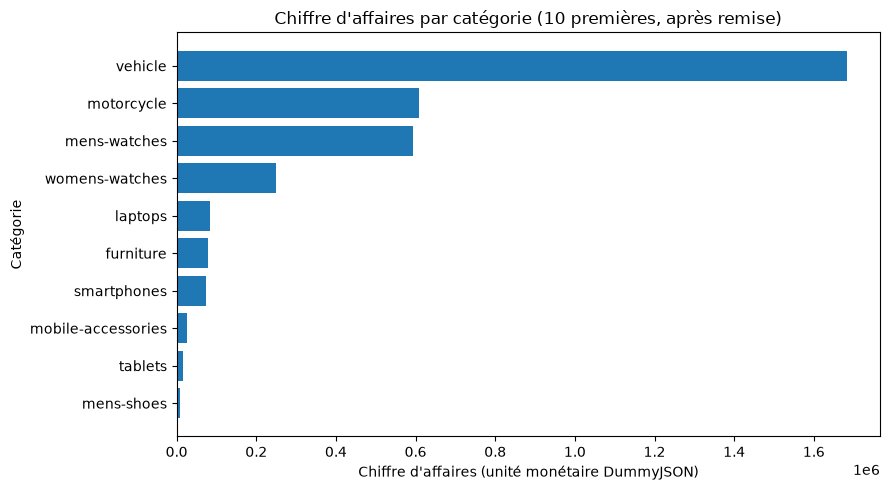

Part de la 1re catégorie : vehicle 48.7 %
Part des 4 premières : 90.7 %


In [10]:
top_cat = ca_categorie.head(10).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_cat.index, top_cat.values)
ax.set_title("Chiffre d'affaires par catégorie (10 premières, après remise)")
ax.set_xlabel("Chiffre d'affaires (unité monétaire DummyJSON)")
ax.set_ylabel("Catégorie")
plt.tight_layout()
plt.savefig(GRAPHIQUES / "1_ca_par_categorie.png", dpi=150)
plt.show()

part = ca_categorie / ca_categorie.sum() * 100
print("Part de la 1re catégorie :", ca_categorie.index[0], f"{part.iloc[0]:.1f} %")
print("Part des 4 premières :", f"{part.head(4).sum():.1f} %")

**Interprétation :** le chiffre d'affaires est très concentré. La catégorie `vehicle` représente à elle seule près de la moitié du total, et les 4 premières catégories (véhicules, motos, montres homme et femme) environ 90 %. Ce sont des produits très chers vendus en petites quantités : la boutique dépend fortement de quelques catégories haut de gamme.

## 5. Graphique 2 — Évolution mensuelle des encaissements
Paiements `PAID` uniquement, somme de `amount` par mois de `payment_date`.

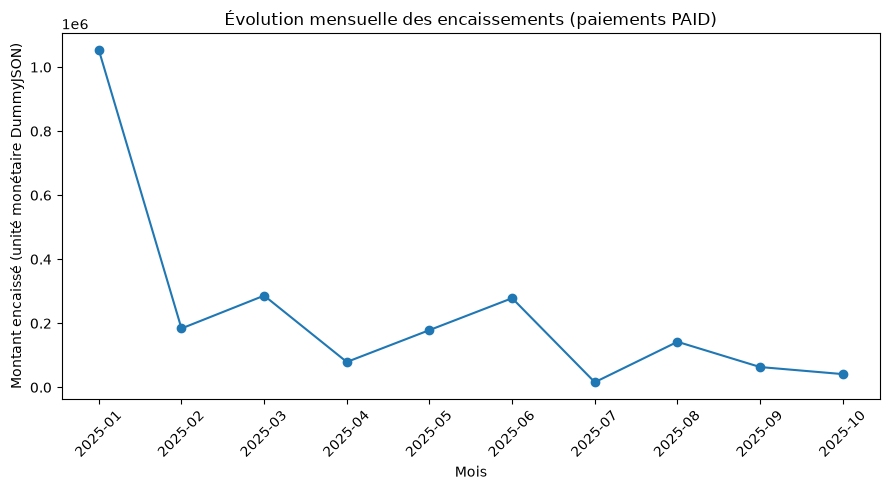

Mois le plus élevé : 2025-01 1053546.98
Mois le plus faible : 2025-07 15897.94


In [11]:
mensuel = (paid.groupby(paid["payment_date"].dt.to_period("M"))["amount"]
           .sum().round(2))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(mensuel.index.astype(str), mensuel.values, marker="o")
ax.set_title("Évolution mensuelle des encaissements (paiements PAID)")
ax.set_xlabel("Mois")
ax.set_ylabel("Montant encaissé (unité monétaire DummyJSON)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(GRAPHIQUES / "2_evolution_mensuelle.png", dpi=150)
plt.show()

print("Mois le plus élevé :", mensuel.idxmax(), mensuel.max())
print("Mois le plus faible :", mensuel.idxmin(), mensuel.min())

**Interprétation :** les encaissements varient fortement d'un mois à l'autre, avec un pic et un creux bien marqués (voir les valeurs affichées). Ces écarts dépendent surtout de la présence ou non d'un panier très cher dans le mois. Attention : `payment_date` vient d'une date **synthétique**, cette courbe ne montre donc aucune vraie saisonnalité.

## 6. Graphique 3 — Top 10 clients pseudonymisés
Somme de `amount` des paiements `PAID` par `user_id_pseudo`. Seuls les 10 premiers caractères du pseudonyme sont affichés.

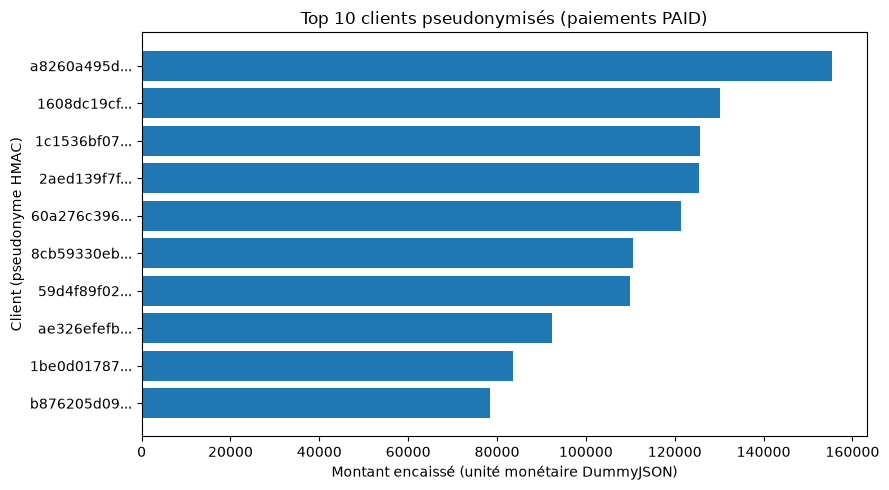

Total du Top 10 : 1133081.49 soit 48.8% des encaissements


In [12]:
top10 = (paid.groupby("user_id_pseudo")["amount"].sum().round(2)
         .sort_values(ascending=False).head(10))
labels = [p[:10] + "..." for p in top10.index]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(labels[::-1], top10.values[::-1])
ax.set_title("Top 10 clients pseudonymisés (paiements PAID)")
ax.set_xlabel("Montant encaissé (unité monétaire DummyJSON)")
ax.set_ylabel("Client (pseudonyme HMAC)")
plt.tight_layout()
plt.savefig(GRAPHIQUES / "3_top10_clients.png", dpi=150)
plt.show()

print("Total du Top 10 :", round(top10.sum(), 2),
      f"soit {top10.sum() / paid['amount'].sum():.1%} des encaissements")

**Interprétation :** les 10 meilleurs clients représentent près de la moitié des encaissements, alors qu'ils ne sont que 10 sur 208. Comme chaque client n'a qu'un panier dans DummyJSON, ce classement reflète surtout les paniers contenant des produits chers. L'analyse est faite sans connaître l'identité des clients, uniquement avec leur pseudonyme.

## 7. Dashboard Streamlit
Le dashboard (`dashboard.py`, à la racine du projet) lit les fichiers Parquet de `data/analytique/`. Pour le lancer, dans le terminal :

```bash
streamlit run dashboard.py
```